# Parte Específica: Visualização exploratória 4

**Variáveis:** `Total_Trans_Ct` (quantidade de transações em 12 meses) e `Total_Trans_Amt` (valor total
transacionado em 12 meses, em US$), com a cor indicando a situação do cliente (`Attrition_Flag`).

**Tipo de gráfico:** dispersão (opção A escolhida pelo grupo).

In [1]:
# [IA] Claude Code – importação das bibliotecas, leitura do dataset tratado, rótulos e cores do grupo
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from taxas import taxa_do_recorte, taxa_por_categoria

CAMINHO_DADOS = Path("../../out/parte_especifica/bankchurners_tratado.csv")
PASTA_SAIDA = Path("../../out/parte_especifica")
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

# As mesmas cores do grupo em todos os gráficos: azul = ficou, vermelho = cancelou
ROTULOS_SITUACAO = {"Existing Customer": "Ficou", "Attrited Customer": "Cancelou"}
ORDEM_SITUACAO = ["Ficou", "Cancelou"]
CORES_SITUACAO = {"Ficou": "#4C72B0", "Cancelou": "#C44E52"}
ALVO, CANCELOU = "Attrition_Flag", "Attrited Customer"

df = pd.read_csv(CAMINHO_DADOS)
df["Situacao"] = df[ALVO].map(ROTULOS_SITUACAO)
assert df["Situacao"].notna().all()
taxa_base = (df[ALVO] == CANCELOU).mean() * 100
print(f"{len(df)} clientes | taxa de cancelamento da base: {taxa_base:.1f}%")

10127 clientes | taxa de cancelamento da base: 16.1%


In [2]:
# [IA] Claude Code – números que acompanham o gráfico: medianas por grupo, correlação e a região de poucas transações e valor baixo
resumo = df.groupby("Situacao")[["Total_Trans_Ct", "Total_Trans_Amt"]].median().reindex(ORDEM_SITUACAO)
print("Medianas por situação:")
display(resumo)

correlacao = df["Total_Trans_Ct"].corr(df["Total_Trans_Amt"])
print(f"Correlação entre transações e valor: {correlacao:.2f}")

# Região do canto inferior esquerdo: menos de 60 transações e menos de US$ 3.000
canto = (df["Total_Trans_Ct"] < 60) & (df["Total_Trans_Amt"] < 3000)
cancelou = df[ALVO] == CANCELOU
print(f"Região (< 60 transações e < US$ 3.000): {canto.sum()} clientes")
print(f"  taxa de cancelamento na região: {taxa_do_recorte(df, canto, ALVO, CANCELOU):.1f}% (base: {taxa_base:.1f}%)")
print(f"  fatia de todos os cancelamentos que está na região: {canto[cancelou].mean() * 100:.1f}%")

# Segundo grupo que a dispersão revela: valores entre US$ 6.000 e 11.000 têm taxa alta
faixa_media = df["Total_Trans_Amt"].between(6000, 11000)
print(f"Faixa US$ 6.000 a 11.000: {faixa_media.sum()} clientes, "
      f"{taxa_do_recorte(df, faixa_media, ALVO, CANCELOU):.1f}% cancelam, "
      f"{faixa_media[cancelou].mean() * 100:.1f}% de todos os cancelamentos")
muito_alto = df["Total_Trans_Amt"] > 11000
print(f"Acima de US$ 11.000: {muito_alto.sum()} clientes, {cancelou[muito_alto].sum()} cancelaram")
intermediaria = (df["Total_Trans_Amt"] >= 3000) & (df["Total_Trans_Amt"] < 6000)
print(f"Faixa US$ 3.000 a 6.000: {intermediaria.sum()} clientes, "
      f"{taxa_do_recorte(df, intermediaria, ALVO, CANCELOU):.1f}% cancelam")
print(f"A região (< 60 transações e < US$ 3.000) é {canto.mean() * 100:.1f}% da base")

Medianas por situação:


,Total_Trans_Ct,Total_Trans_Amt
Situacao,,
Ficou,71.0,4100.0
Cancelou,43.0,2329.0


Correlação entre transações e valor: 0.81
Região (< 60 transações e < US$ 3.000): 3535 clientes
  taxa de cancelamento na região: 35.9% (base: 16.1%)
  fatia de todos os cancelamentos que está na região: 77.9%
Faixa US$ 6.000 a 11.000: 703 clientes, 32.0% cancelam, 13.8% de todos os cancelamentos
Acima de US$ 11.000: 747 clientes, 0 cancelaram
Faixa US$ 3.000 a 6.000: 4782 clientes, 2.5% cancelam
A região (< 60 transações e < US$ 3.000) é 34.9% da base


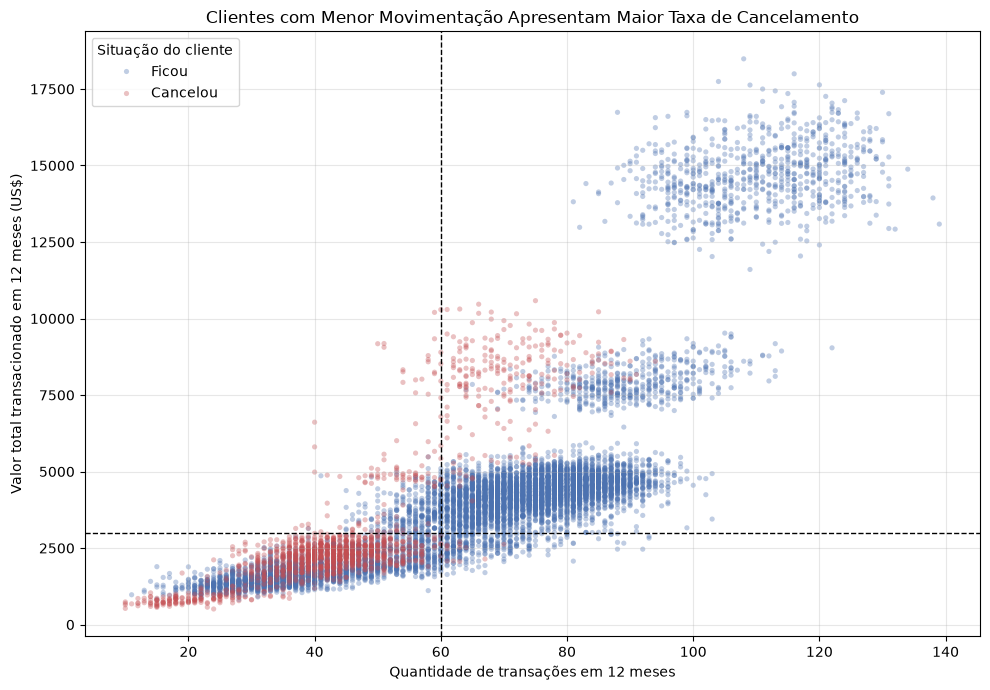

In [3]:
# [IA] Claude Code – gráfico de dispersão de transações x valor transacionado, colorido por situação do cliente
fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(
    data=df, x="Total_Trans_Ct", y="Total_Trans_Amt",
    hue="Situacao", hue_order=ORDEM_SITUACAO, palette=CORES_SITUACAO,
    alpha=0.35, s=14, edgecolor="none", ax=ax,
)
# Linhas tracejadas marcam a região comentada na nota analítica
ax.axvline(60, color="black", linestyle="--", linewidth=1)
ax.axhline(3000, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Quantidade de transações em 12 meses")
ax.set_ylabel("Valor total transacionado em 12 meses (US$)")
ax.set_title('Clientes com Menor Movimentação Apresentam Maior Taxa de Cancelamento')
ax.legend(title="Situação do cliente")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "viz_exploratoria_4_dispersao_trans_ct_amt.png", dpi=150, bbox_inches="tight")
plt.show()

**Cortes de 60 transações e US$ 3.000 (definidos pelo Fernando):** Escolhi esses valores como referências para separar clientes com menor e maior movimentação, facilitando a comparação das taxas de cancelamento entre os grupos.


## Nota analítica

**O que está sendo mostrado:** O gráfico mostra a relação entre a quantidade de transações e o valor total que cada cliente movimentou em 12 meses. Cada ponto representa um cliente, e as cores diferenciam quem continuou no banco de quem cancelou.

**Qual insight pode ser extraído:** Existe uma relação positiva entre a quantidade de transações e o valor movimentado, com correlação de 0,81. Além disso, clientes que cancelaram costumam ter menos transações e movimentar menos dinheiro. O principal alerta está na região abaixo de 60 transações e US$ 3.000: ela concentra 34,9% dos clientes, mas reúne 77,9% de todos os cancelamentos. Isso indica que clientes com pouca movimentação merecem atenção do banco.

**Por que este tipo de visualização:** Porque esse tipo de gráfico permite observar a relação entre duas variáveis numéricas ao mesmo tempo. Também facilita identificar concentrações de clientes, padrões, diferenças entre quem ficou e quem cancelou e possíveis grupos de maior risco. As linhas tracejadas ajudam a separar as regiões para a análise.
